# Классификация NIRS-сигналов


В ноутбуке рассматривается обработка и классификация сигналов функциональной ближней инфракрасной спектроскопии (fNIRS) из первой серии экспериментов диссертации М. Р. Исаева.

Исследуются влияние предобработки сигналов и отбора каналов на качество классификации, а также возможность улучшения результатов за счёт использования данных предыдущих блоков и сессий. Сравниваются методы LDA, QDA, SVM и CatBoost.

Рассматриваются две задачи: различение движений левой и правой руки (`left_vs_right`) и различение состояния покоя и двигательной активности (`rest_vs_active`).

## 1. Импорты и настройка путей

In [1]:
from pathlib import Path
import yaml
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from nirs_bci.data import load_all_days, summarize_days
from nirs_bci.evaluation import aggregate_lobo_by_day, summarize_median_iqr, summarize_experiment_grid
from nirs_bci.experiments import run_subject_filter_experiments, precompute_filters, run_experiment_grid
from nirs_bci.channel_selection import run_lobo_one_day_with_channel_selection
from nirs_bci.spectral import make_fnirs_bands, band_power_summary_hbo_hbr, normalize_band_power_to_raw
from nirs_bci.visualization import (
    plot_psd_hbo_hbr, plot_channel_selection_boxplot,
    plot_dissertation_style_with_summary, plot_lda_qda_filter_boxplot,
)

ROOT = Path.cwd().resolve()
ROOT = next(
    (folder for folder in (ROOT, *ROOT.parents)
     if (folder / "pyproject.toml").is_file() and (folder / "configs").is_dir()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Откройте ноутбук внутри каталога проекта nirs-bci-classification.")
config = yaml.safe_load((ROOT / "configs/nirs_bci.yaml").read_text(encoding="utf-8"))
data_root = ROOT / config["paths"]["data_root"]
results_root = ROOT / config["paths"]["output_root"]

psd_dir = results_root / "01_psd_filters"
baseline_dir = results_root / "02_lda_qda_baseline"
channel_dir = results_root / "03_channel_selection"
prev_dir = results_root / "04_previous_blocks_sessions"
for folder in (psd_dir, baseline_dir, channel_dir, prev_dir):
    folder.mkdir(parents=True, exist_ok=True)

[local path]: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Загрузка данных

In [2]:
if not list(data_root.glob("Day_*.mat")):
    raise FileNotFoundError(f"Добавьте Day_*.mat в {data_root}")
days = load_all_days(data_root)
df_summary = summarize_days(days)

df_summary

,file,day,subject,n_time,n_channels,n_features,fs,duration_sec,duration_min,class_counts
0,Day_1.mat,1,Mihail,2346,33,66,3.90625,600.576,10.009600,"{0: 470, 1: 938, 2: 470, 3: 468}"
1,Day_2.mat,2,Mihail,2402,33,66,3.90625,614.912,10.248533,"{0: 526, 1: 938, 2: 470, 3: 468}"
2,Day_3.mat,3,Mihail,2217,33,66,3.90625,567.552,9.459200,"{0: 341, 1: 938, 2: 469, 3: 469}"
3,Day_4.mat,4,Mihail,2230,33,66,3.90625,570.880,9.514667,"{0: 354, 1: 938, 2: 470, 3: 468}"
4,Day_5.mat,5,Mihail,2301,33,66,3.90625,589.056,9.817600,"{0: 425, 1: 938, 2: 470, 3: 468}"
5,Day_6.mat,6,Mihail,2323,33,66,3.90625,594.688,9.911467,"{0: 447, 1: 938, 2: 469, 3: 469}"
6,Day_7.mat,7,Mihail,2265,33,66,3.90625,579.840,9.664000,"{0: 389, 1: 938, 2: 470, 3: 468}"
7,Day_8.mat,8,Mihail,2255,33,66,3.90625,577.280,9.621333,"{0: 379, 1: 938, 2: 470, 3: 468}"


In [3]:
for d in days:
    print("\n", d["file_name"])
    print("n_trials =", len(d["trials"]))
    print("n_blocks =", d["trials"]["block_id"].nunique())
    print(d["trials"].groupby(["block_id", "label"]).size().unstack(fill_value=0))


 Day_1.mat
n_trials = 24
n_blocks = 3
label     1  2  3
block_id         
0         4  2  2
1         4  2  2
2         4  2  2

 Day_2.mat
n_trials = 24
n_blocks = 3
label     1  2  3
block_id         
0         4  2  2
1         4  2  2
2         4  2  2

 Day_3.mat
n_trials = 24
n_blocks = 3
label     1  2  3
block_id         
0         4  2  2
1         4  2  2
2         4  2  2

 Day_4.mat
n_trials = 24
n_blocks = 3
label     1  2  3
block_id         
0         4  2  2
1         4  2  2
2         4  2  2

 Day_5.mat
n_trials = 24
n_blocks = 3
label     1  2  3
block_id         
0         4  2  2
1         4  2  2
2         4  2  2

 Day_6.mat
n_trials = 24
n_blocks = 3
label     1  2  3
block_id         
0         4  2  2
1         4  2  2
2         4  2  2

 Day_7.mat
n_trials = 24
n_blocks = 3
label     1  2  3
block_id         
0         4  2  2
1         4  2  2
2         4  2  2

 Day_8.mat
n_trials = 24
n_blocks = 3
label     1  2  3
block_id         
0         4  2  2
1   

## 3. Общие настройки

In [3]:
filters_active = config["filters"]["filters_active"]

filters_rest_active = config["filters"]["filters_rest_active"]

filters_psd = config["filters"]["filters_psd"]

filter_labels = config["filters"]["filter_labels"]

## 4. Спектральная плотность мощности (PSD)

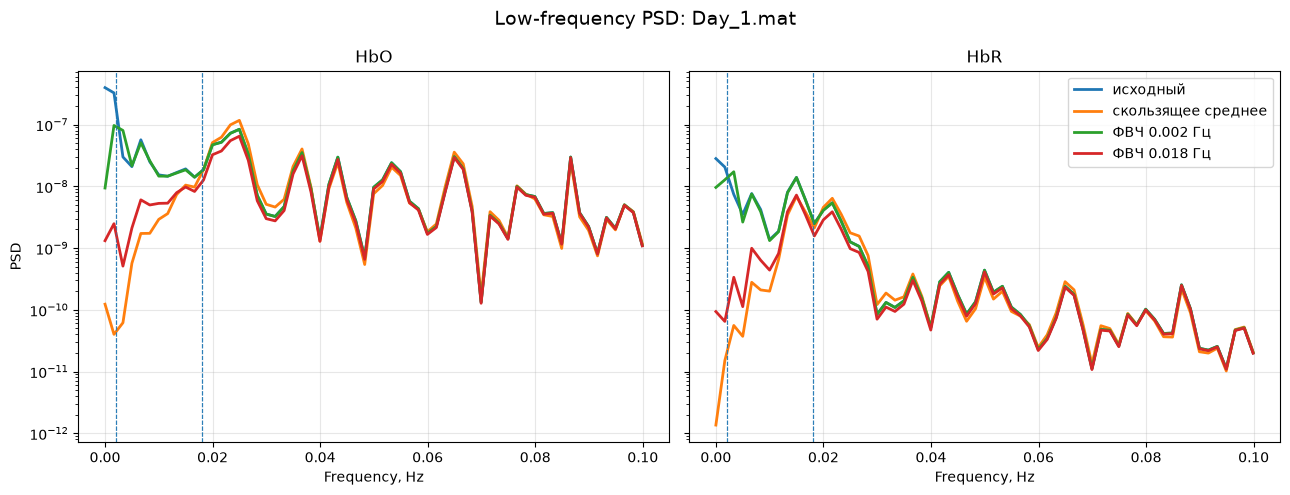

In [4]:
fig, axes = plot_psd_hbo_hbr(
    day=days[0],
    filters=filters_psd,
    filter_labels=filter_labels,
    max_freq=config["psd"]["max_freq"],
)

plt.show()

In [5]:
bands = make_fnirs_bands(days[0]["sampling_rate"])
band_table = band_power_summary_hbo_hbr(
    day=days[0], filters=filters_psd, bands=bands, filter_labels=filter_labels,
)
band_cols = [band[0] for band in bands]
band_table_rel = normalize_band_power_to_raw(band_table=band_table, band_cols=band_cols)
band_table_report = band_table_rel[
    ["filter_label", "component"] + [f"{col}_rel_to_raw" for col in band_cols]
]
display(band_table_report)
band_table_report.to_csv(psd_dir / "band_power_relative_day1.csv", index=False, encoding="utf-8-sig")
fig.savefig(psd_dir / "psd_hbo_hbr_day1.png", dpi=300, bbox_inches="tight")


,filter_label,component,very_slow_<0.01_rel_to_raw,mayer_0.01_0.05_rel_to_raw,respiration_0.1_0.5_rel_to_raw,heart_0.8_2.0_rel_to_raw
0,исходный,HbO,1.000000,1.000000,1.000000,1.000000
1,исходный,HbR,1.000000,1.000000,1.000000,1.000000
2,скользящее среднее,HbO,0.008488,1.134896,1.025457,0.999549
3,скользящее среднее,HbR,0.012021,0.765741,1.011321,0.999869
4,ФВЧ 0.002 Гц,HbO,0.432475,0.995156,0.999874,0.999999
5,ФВЧ 0.002 Гц,HbR,0.852753,0.992804,0.999942,0.999999
6,ФВЧ 0.018 Гц,HbO,0.029219,0.755775,0.989579,0.999912
7,ФВЧ 0.018 Гц,HbR,0.041514,0.605646,0.994442,0.999941


Сравнение относительной мощности спектральных компонент показывает, что применённые методы предобработки преимущественно подавляют очень низкие частоты (ниже 0.01 Гц). Наиболее сильное подавление наблюдается при удалении тренда скользящим средним и использовании ФВЧ с частотой среза 0.018 Гц. При этом мощность в диапазонах дыхательных и сердечных колебаний практически не изменяется.

## 5. Офлайн сравнение LDA/QDA по фильтрам

### 5.1 Запуск LDA/QDA для классификации left vs right

In [6]:
results_active_lda = run_subject_filter_experiments(
    days=days,
    task="left_vs_right",
    filters=filters_active,
    model_name="LDA",
)

results_active_qda = run_subject_filter_experiments(
    days=days,
    task="left_vs_right",
    filters=filters_active,
    model_name="QDA",
)

agg_active_lda = aggregate_lobo_by_day(results_active_lda)
agg_active_qda = aggregate_lobo_by_day(results_active_qda)

summary_active_lda = summarize_median_iqr(
    aggregated=agg_active_lda,
    filters=filters_active,
    filter_labels=filter_labels,
    digits=3,
)

summary_active_qda = summarize_median_iqr(
    aggregated=agg_active_qda,
    filters=filters_active,
    filter_labels=filter_labels,
    digits=3,
)

### 5.2 Запуск LDA/QDA для классификации rest vs active

In [7]:
results_rest_lda = run_subject_filter_experiments(
    days=days,
    task="rest_vs_active",
    filters=filters_rest_active,
    model_name="LDA",
)

results_rest_qda = run_subject_filter_experiments(
    days=days,
    task="rest_vs_active",
    filters=filters_rest_active,
    model_name="QDA",
)

agg_rest_lda = aggregate_lobo_by_day(results_rest_lda)
agg_rest_qda = aggregate_lobo_by_day(results_rest_qda)

summary_rest_lda = summarize_median_iqr(
    aggregated=agg_rest_lda,
    filters=filters_rest_active,
    filter_labels=filter_labels,
    digits=3,
)

summary_rest_qda = summarize_median_iqr(
    aggregated=agg_rest_qda,
    filters=filters_rest_active,
    filter_labels=filter_labels,
    digits=3,
)

In [8]:
report_models = pd.concat([
    summary.assign(**{"Задача": task, "Модель": model})
    for summary, task, model in [
        (summary_active_lda, "Активные состояния", "LDA"),
        (summary_active_qda, "Активные состояния", "QDA"),
        (summary_rest_lda, "Покой–активность", "LDA"),
        (summary_rest_qda, "Покой–активность", "QDA"),
    ]
], ignore_index=True)
report_models = report_models[
    ["Задача", "Модель", "filter_label", "n", "P_median_iqr"]
].rename(columns={"filter_label": "Фильтрация", "P_median_iqr": "P, медиана [25%; 75%]"})
display(report_models)
report_models.to_csv(baseline_dir / "report_lda_qda_filters.csv", index=False, encoding="utf-8-sig")
for name, frame in {
    "results_active_lda": results_active_lda,
    "results_active_qda": results_active_qda,
    "results_rest_lda": results_rest_lda,
    "results_rest_qda": results_rest_qda,
}.items():
    frame.to_csv(baseline_dir / f"{name}.csv", index=False, encoding="utf-8-sig")


,Задача,Модель,Фильтрация,n,"P, медиана [25%; 75%]"
0,Активные состояния,LDA,исходный,8,0.520 [0.496; 0.566]
1,Активные состояния,LDA,скользящее среднее,8,0.581 [0.520; 0.596]
2,Активные состояния,LDA,ФВЧ 0.002 Гц,8,0.561 [0.518; 0.575]
3,Активные состояния,QDA,исходный,8,0.507 [0.500; 0.545]
4,Активные состояния,QDA,скользящее среднее,8,0.557 [0.463; 0.588]
5,Активные состояния,QDA,ФВЧ 0.002 Гц,8,0.518 [0.429; 0.555]
6,Покой–активность,LDA,исходный,8,0.590 [0.566; 0.664]
7,Покой–активность,LDA,скользящее среднее,8,0.794 [0.723; 0.820]
8,Покой–активность,LDA,ФВЧ 0.002 Гц,8,0.611 [0.580; 0.631]
9,Покой–активность,LDA,ФВЧ 0.018 Гц,8,0.709 [0.672; 0.751]


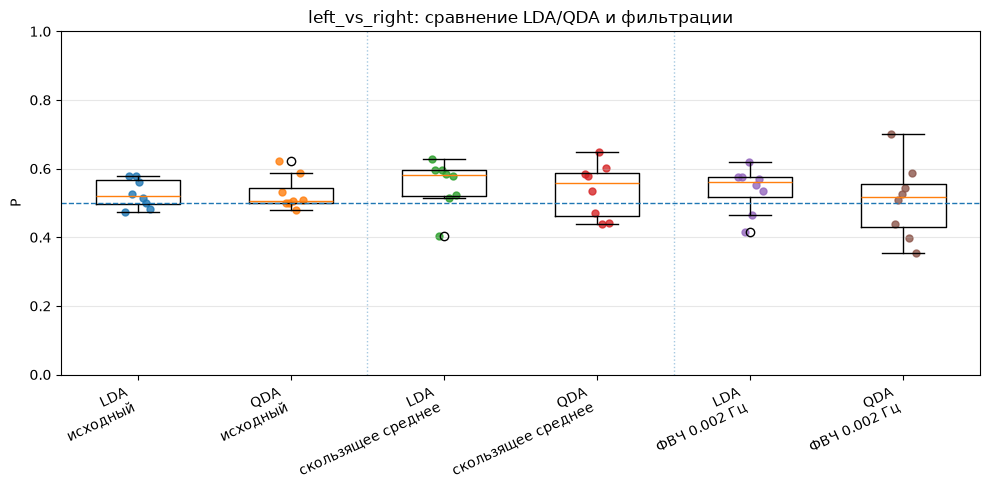

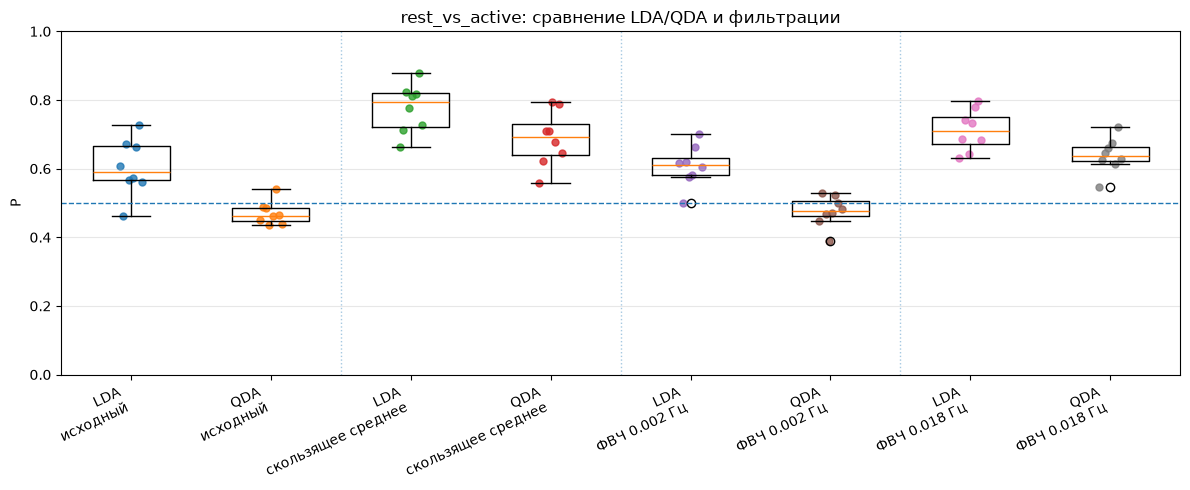

In [10]:
for task, agg_lda, agg_qda, filters, size in [
    ("left_vs_right", agg_active_lda, agg_active_qda, filters_active, (10, 5)),
    ("rest_vs_active", agg_rest_lda, agg_rest_qda, filters_rest_active, (12, 5)),
]:
    fig, ax = plot_lda_qda_filter_boxplot(
        agg_lda=agg_lda, agg_qda=agg_qda, filters=filters,
        filter_labels=filter_labels,
        title=f"{task}: сравнение LDA/QDA и фильтрации",
        chance_level=0.5, figsize=size,
    )
    plt.show()
    fig.savefig(baseline_dir / f"{task}_LDA_QDA_filters_boxplot.png", dpi=300, bbox_inches="tight")


### Вывод по классификаторам LDA/QDA

Для каждой сессии использовалась схема leave-one-block-out: два блока использовались для обучения, один блок - для тестирования. Значение качества P усреднялось по трём фолдам внутри дня, после чего по дням вычислялись медиана, 25-й и 75-й процентили.

Для задачи `left_vs_right` качество оказалось близким к случайному уровню. Это указывает на слабую разделимость двух активных состояний по текущим БИКС-признакам.

Для задачи `rest_vs_active` качество существенно выше, что согласуется с тем, что общий гемодинамический ответ на активное состояние выделяется надёжнее, чем различие между левой и правой рукой.

Сравнение LDA и QDA показывает, что LDA на доступных данных оказывается более устойчивым. Это ожидаемо, поскольку QDA требует оценки отдельной ковариационной матрицы для каждого класса, что при ограниченном числе обучающих данных может приводить к менее стабильным оценкам.

## 6. Отбор значимых каналов

,method,Метод отбора,n,Медианное число каналов,median,q25,q75,"P, медиана [25%; 75%]"
0,all_channels,все каналы,8,33.0,0.561404,0.517544,0.574561,0.561 [0.518; 0.575]
1,best_single,лучший одиночный канал,8,1.0,0.486842,0.472588,0.540570,0.487 [0.473; 0.541]
2,greedy_from_single,жадный от одного канала,8,9.5,0.517544,0.473684,0.593202,0.518 [0.474; 0.593]
3,best_pair,лучшая пара каналов,8,2.0,0.471491,0.432018,0.508772,0.471 [0.432; 0.509]
4,greedy_from_pair,жадный от лучшей пары,8,8.5,0.500000,0.469298,0.541667,0.500 [0.469; 0.542]


selection_method    status
all_channels        ok        24
best_pair           ok        24
best_single         ok        24
greedy_from_pair    ok        24
greedy_from_single  ok        24
dtype: int64

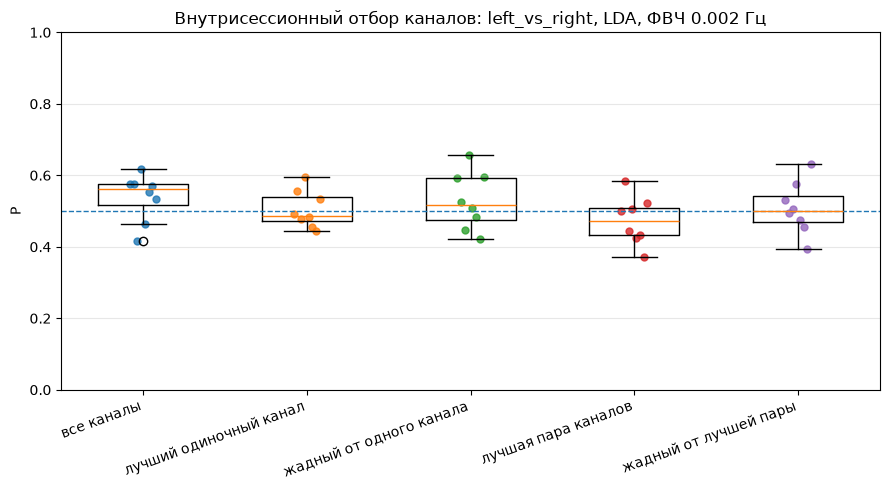

In [11]:
if config["experiments"]["channel_selection"]["enabled"]:
    selection_methods = config["channel_selection"]["selection_methods"]
    method_labels = config["channel_selection"]["method_labels"]
    if len(days) != 8 or any(day["X"].shape[1] != 66 for day in days):
        raise ValueError("Для отбора каналов нужны восемь сессий с 33 парами HbO/HbR")
    results_within_session = pd.concat([
        run_lobo_one_day_with_channel_selection(
            day=day, task="left_vs_right", model_name="LDA",
            filter_mode="highpass_0002", selection_method=method, window_sec=1.0,
        )
        for day in days for method in selection_methods
    ], ignore_index=True)
    results_within_session.to_csv(channel_dir / "results_channel_selection.csv", index=False, encoding="utf-8-sig")

    daily_tables, reports = [], []
    for method in selection_methods:
        folds = results_within_session.loc[results_within_session["selection_method"] == method]
        daily = aggregate_lobo_by_day(folds)
        keys = ["file", "day", "subject", "task", "model", "filter"]
        channel_counts = folds.loc[folds["status"] == "ok"].groupby(keys, dropna=False).agg(
            n_selected_channels_median=("n_selected_channels", "median"),
            selection_cv_score_mean=("selection_cv_score", "mean"),
        ).reset_index()
        daily = daily.merge(channel_counts, on=keys, validate="one_to_one")
        daily.insert(len(keys), "selection_method", method)
        daily_tables.append(daily)
        report = summarize_median_iqr(daily, filters=["highpass_0002"])
        report = report.drop(columns=["filter", "filter_label"]).rename(
            columns={"P_median_iqr": "P, медиана [25%; 75%]"}
        )
        report.insert(0, "method", method)
        report.insert(1, "Метод отбора", method_labels[method])
        report.insert(3, "Медианное число каналов", daily["n_selected_channels_median"].median())
        reports.append(report)
    agg_within_session = pd.concat(daily_tables, ignore_index=True)
    report_within_session = pd.concat(reports, ignore_index=True)
    agg_within_session.to_csv(channel_dir / "agg_channel_selection_by_day.csv", index=False, encoding="utf-8-sig")
    report_within_session.to_csv(channel_dir / "report_channel_selection.csv", index=False, encoding="utf-8-sig")
    display(report_within_session)
    display(results_within_session.groupby(["selection_method", "status"]).size())
    fig, ax = plot_channel_selection_boxplot(
        aggregated=agg_within_session, selection_methods=selection_methods,
        method_labels=method_labels,
        title="Внутрисессионный отбор каналов: left_vs_right, LDA, ФВЧ 0.002 Гц",
        chance_level=0.5,
    )
    plt.show()
    fig.savefig(channel_dir / "channel_selection_boxplot.png", dpi=300, bbox_inches="tight")
else:
    print("Отбор каналов отключён в configs/nirs_bci.yaml")


Для задачи left_vs_right был дополнительно проверен внутрисессионный отбор каналов. Рассматривались стратегии: 
- лучший одиночный канал
- жадный отбор от одного канала
- лучшая пара каналов
- жадный отбор от лучшей пары

Отбор выполнялся только по обучающим блокам внутри каждого фолда, после чего качество оценивалось на отложенном тестовом блоке.



На доступных данных отбор каналов не дал устойчивого улучшения качества по сравнению с использованием всех каналов. Более того, при фильтрации ФВЧ 0.002 Гц все рассмотренные стратегии отбора каналов показали качество ниже, чем классификация по всем каналам. Поэтому в дальнейшем для базовой классификации использовался вариант со всеми каналами.



Такой результат не противоречит диссертационной логике: отбор каналов является дополнительной процедурой, эффективность которой зависит от конкретного испытуемого, задачи и устойчивости пространственного паттерна. На одном испытуемом и восьми сессиях выбранные каналы могут нестабильно переноситься на тестовый блок.

## 7. Сравнение обучения на предыдущих блоках сессии и на предыдущих сессиях

### 7.1. Обучение на предыдущих блоках и сессиях: LDA, SVM и CatBoost

In [9]:
previous = config["previous_sessions"]
FEATURE_SET = previous["FEATURE_SET"]
CLASSIFIERS = previous["CLASSIFIERS"]
TASK_FILTERS = previous["TASK_FILTERS"]
TASKS = list(TASK_FILTERS)
WINDOW_SEC = previous["WINDOW_SEC"]
preprocessed = precompute_filters(days=days, filters=sorted({f for fs in TASK_FILTERS.values() for f in fs}))
results_exp1_ml, results_exp2_ml = run_experiment_grid(
    preprocessed=preprocessed, task_filters=TASK_FILTERS,
    classifiers=CLASSIFIERS, feature_set=FEATURE_SET,
    window_sec=WINDOW_SEC, seed=previous["SEED"], n_permutations=previous["N_PERMUTATIONS"],
    description="Previous blocks/sessions", days=days,
)
display(results_exp1_ml.groupby(["task", "clf", "filter", "status"]).size())
display(results_exp2_ml.groupby(["task", "clf", "filter", "status"]).size())
results_exp1_ml.to_csv(prev_dir / "results_exp1_lda_svm_catboost.csv", index=False, encoding="utf-8-sig")
results_exp2_ml.to_csv(prev_dir / "results_exp2_lda_svm_catboost.csv", index=False, encoding="utf-8-sig")
results_all_ml = pd.concat([results_exp1_ml, results_exp2_ml], ignore_index=True)
summary_ml = summarize_experiment_grid(
    results_all_ml, ["variant", "task", "clf", "filter"],
    ["task", "filter", "variant", "clf"],
)
display(summary_ml[[
    "variant", "task", "clf", "filter", "n", "P_train_median",
    "P_test, median [25%; 75%]", "gap, median [25%; 75%]",
]])
summary_ml.to_csv(prev_dir / "summary_lda_svm_catboost.csv", index=False, encoding="utf-8-sig")

Previous blocks/sessions: 100%|██████████| 105/105 [09:47<00:00,  5.59s/it]


task            clf                filter         status         
left_vs_right   CatBoost_mean      highpass_0002  no_train_random    24
                                                  ok                 48
                                   sma            no_train_random    24
                                                  ok                 48
                CatBoost_mean_std  highpass_0002  no_train_random    24
                                                                     ..
rest_vs_active  SVM_rbf_mean_std   highpass_0002  ok                 48
                                   highpass_0018  no_train_random    24
                                                  ok                 48
                                   sma            no_train_random    24
                                                  ok                 48
Length: 70, dtype: int64

task            clf                filter         status         
left_vs_right   CatBoost_mean      highpass_0002  no_train_random     3
                                                  ok                 69
                                   sma            no_train_random     3
                                                  ok                 69
                CatBoost_mean_std  highpass_0002  no_train_random     3
                                                                     ..
rest_vs_active  SVM_rbf_mean_std   highpass_0002  ok                 69
                                   highpass_0018  no_train_random     3
                                                  ok                 69
                                   sma            no_train_random     3
                                                  ok                 69
Length: 70, dtype: int64

,variant,task,clf,filter,n,P_train_median,"P_test, median [25%; 75%]","gap, median [25%; 75%]"
0,exp1,left_vs_right,CatBoost_mean,highpass_0002,72,1.000000,0.500 [0.500; 0.513],0.500 [0.428; 0.503]
1,exp1,left_vs_right,CatBoost_mean_std,highpass_0002,72,1.000000,0.500 [0.500; 0.507],0.500 [0.424; 0.516]
2,exp1,left_vs_right,LDA,highpass_0002,72,1.000000,0.500 [0.500; 0.500],0.500 [0.477; 0.513]
3,exp1,left_vs_right,SVM_linear_mean,highpass_0002,72,1.000000,0.500 [0.500; 0.507],0.500 [0.405; 0.500]
4,exp1,left_vs_right,SVM_linear_mean_std,highpass_0002,72,1.000000,0.500 [0.500; 0.500],0.500 [0.477; 0.503]
...,...,...,...,...,...,...,...,...
65,exp2,rest_vs_active,LDA,sma,72,0.831340,0.720 [0.605; 0.809],0.120 [0.035; 0.244]
66,exp2,rest_vs_active,SVM_linear_mean,sma,72,0.853469,0.684 [0.590; 0.803],0.161 [0.062; 0.257]
67,exp2,rest_vs_active,SVM_linear_mean_std,sma,72,0.865789,0.671 [0.572; 0.781],0.207 [0.087; 0.289]
68,exp2,rest_vs_active,SVM_rbf_mean,sma,72,0.915132,0.724 [0.579; 0.811],0.195 [0.092; 0.316]


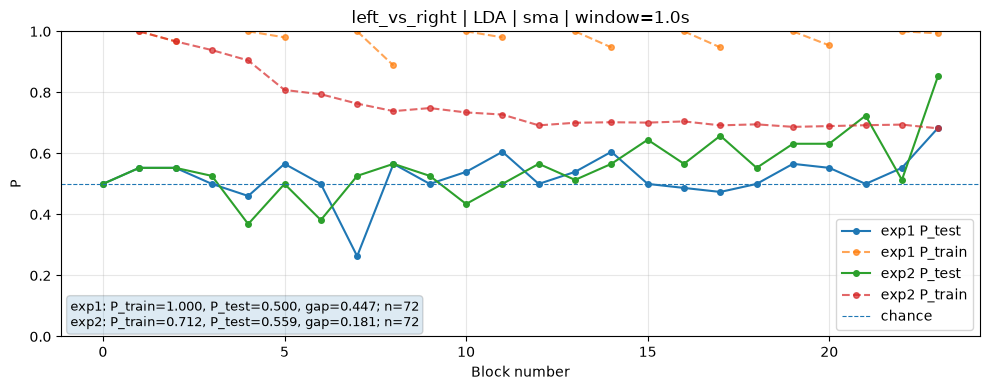

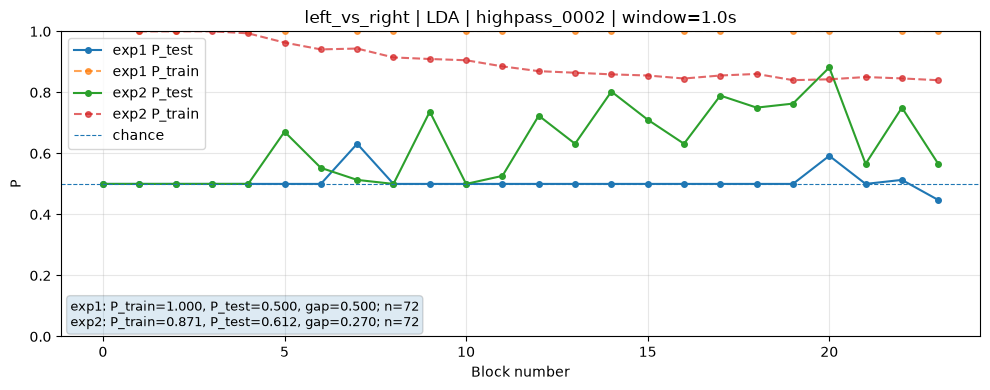

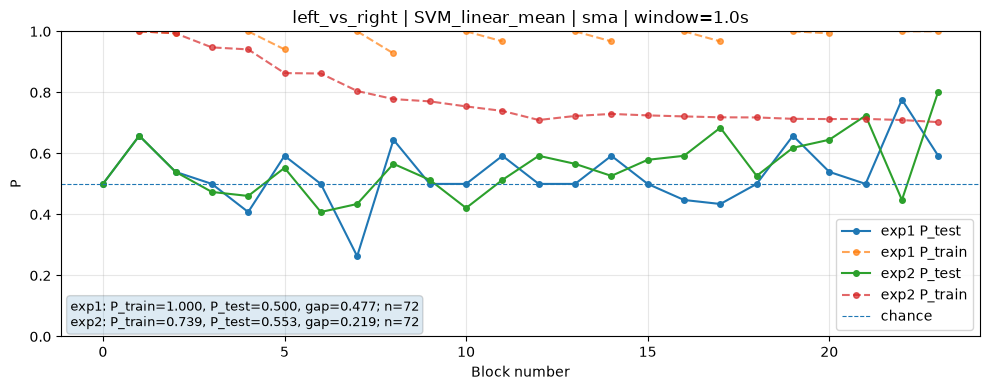

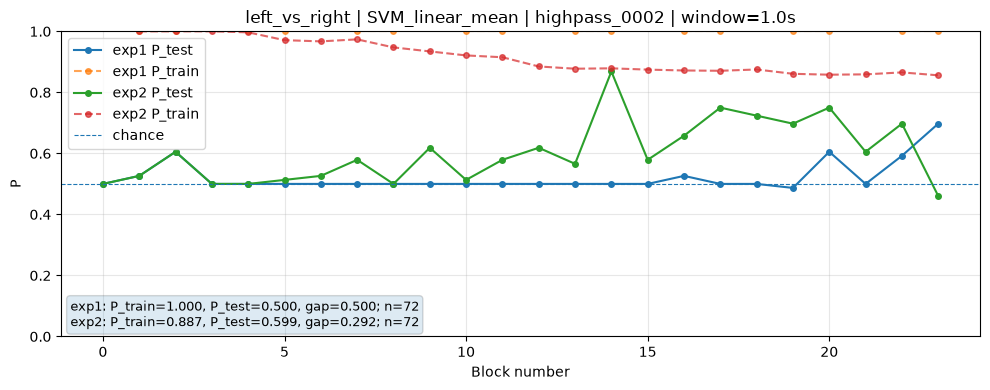

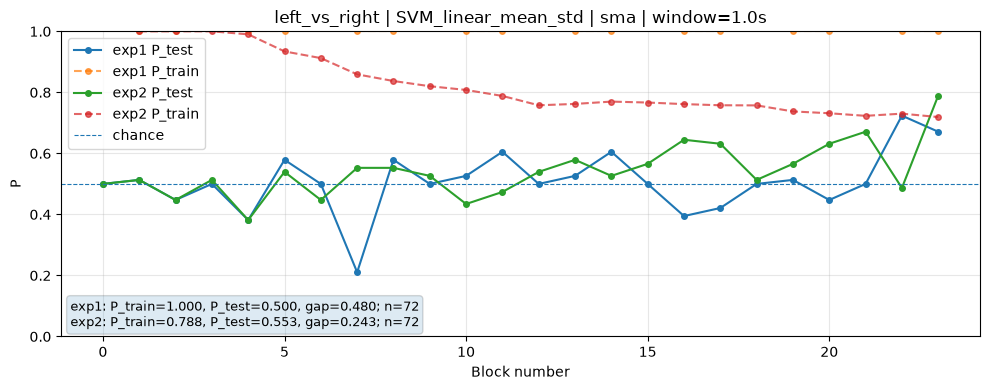

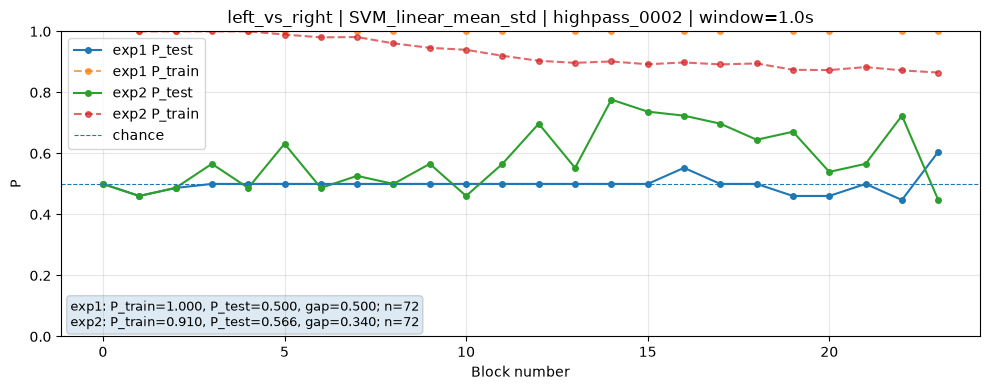

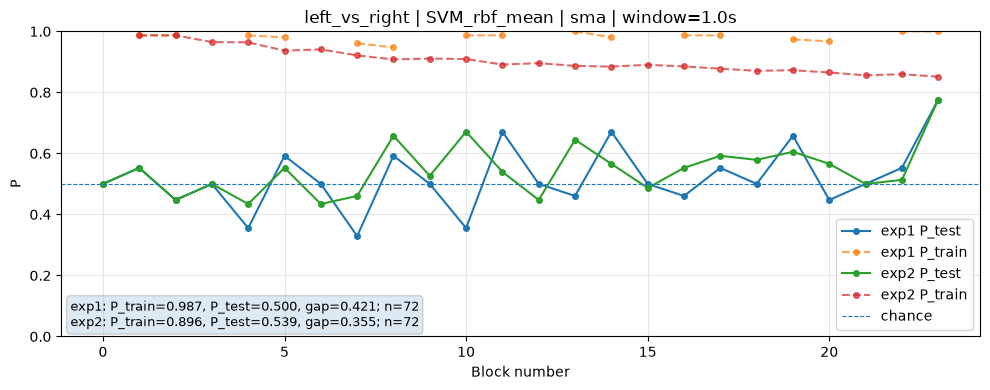

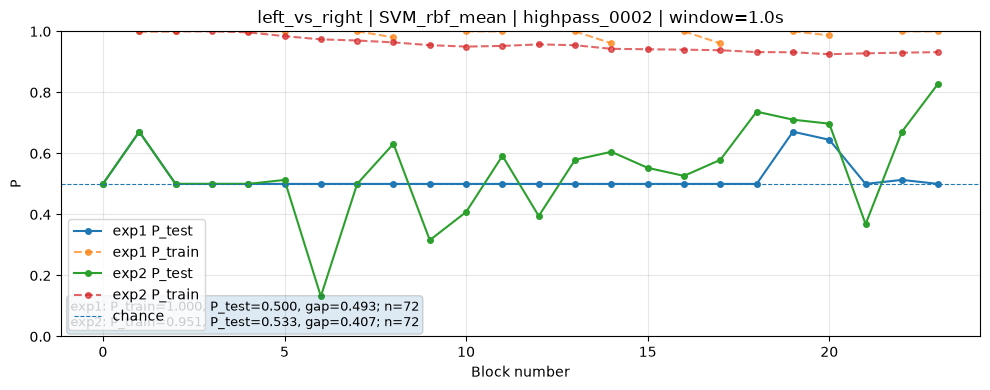

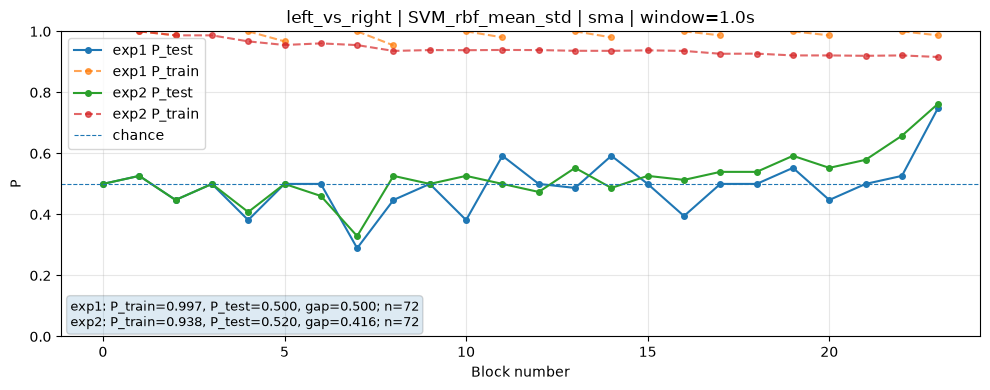

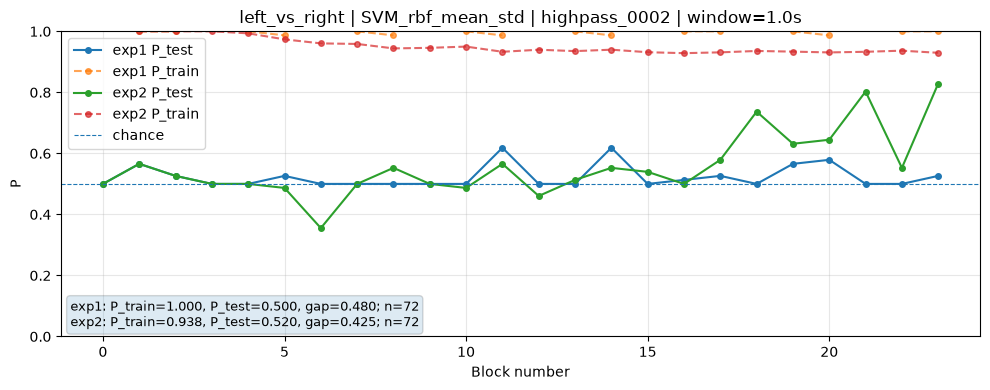

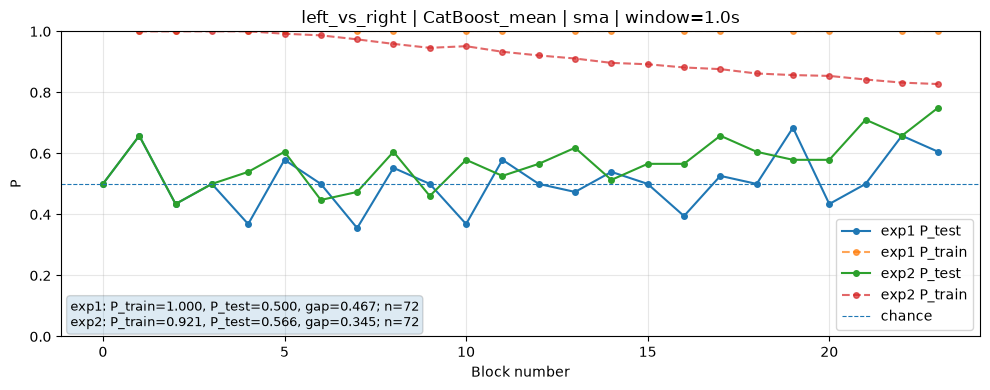

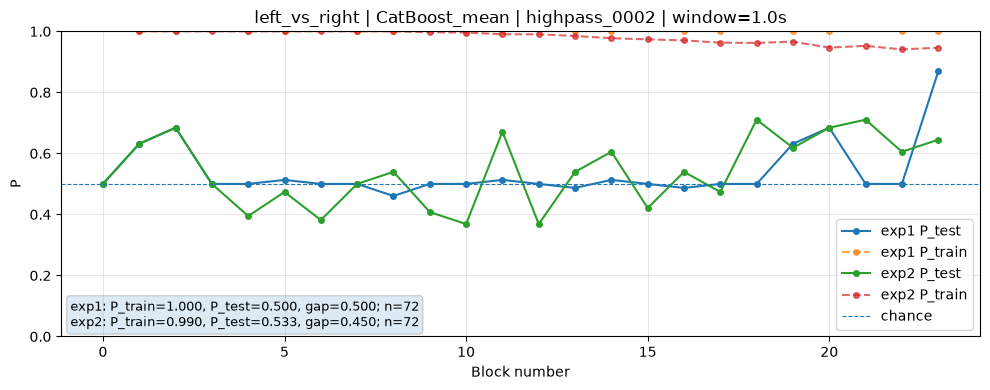

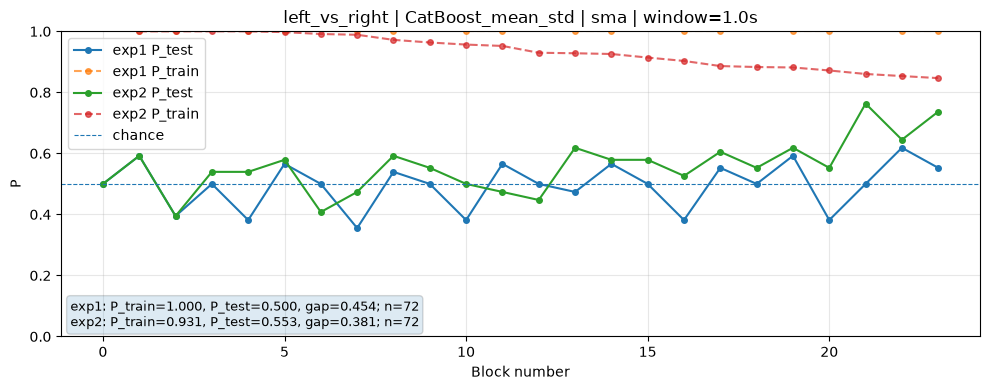

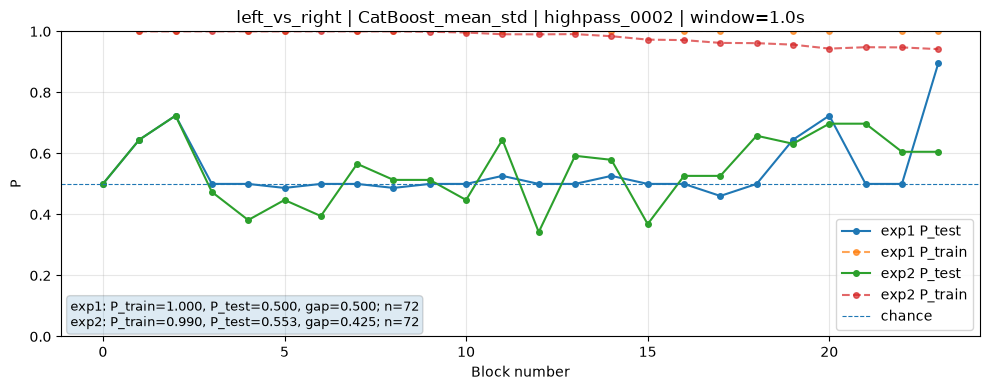

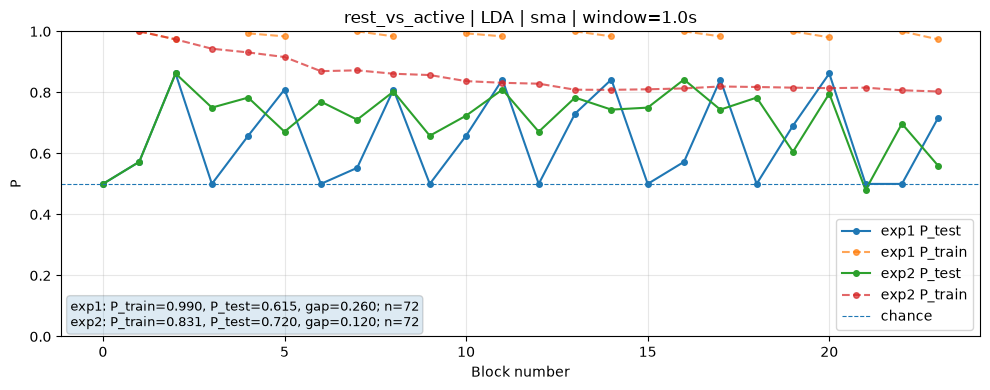

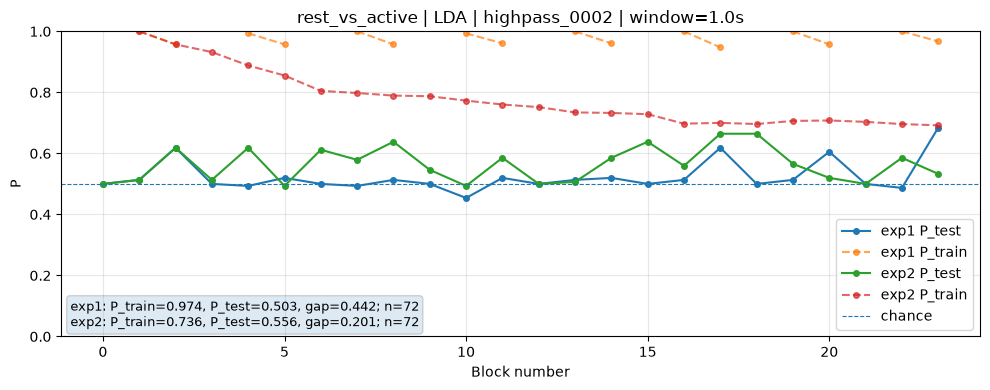

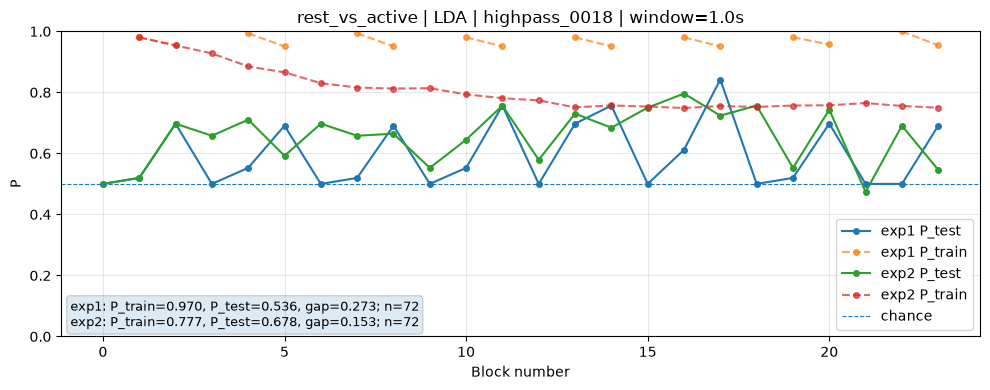

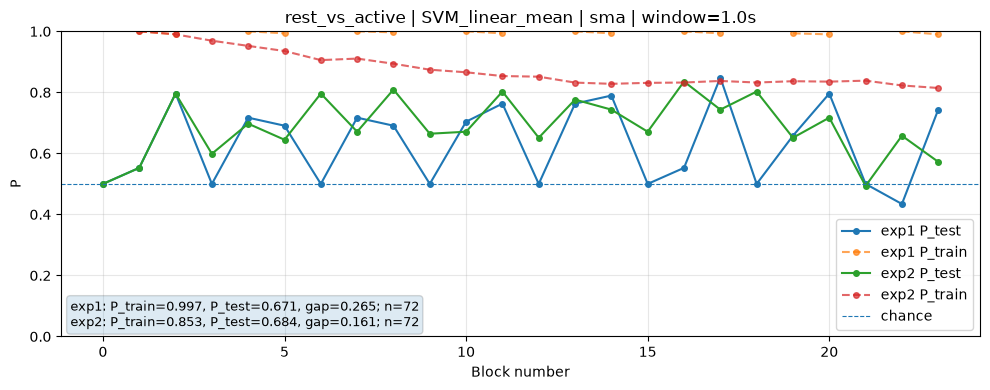

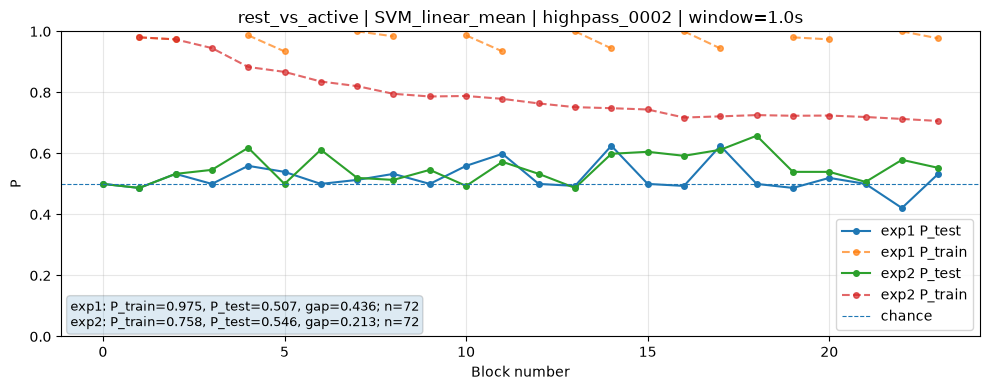

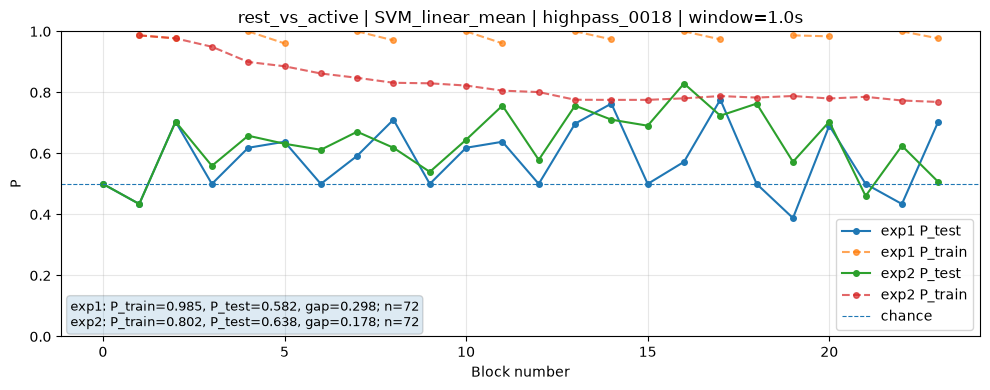

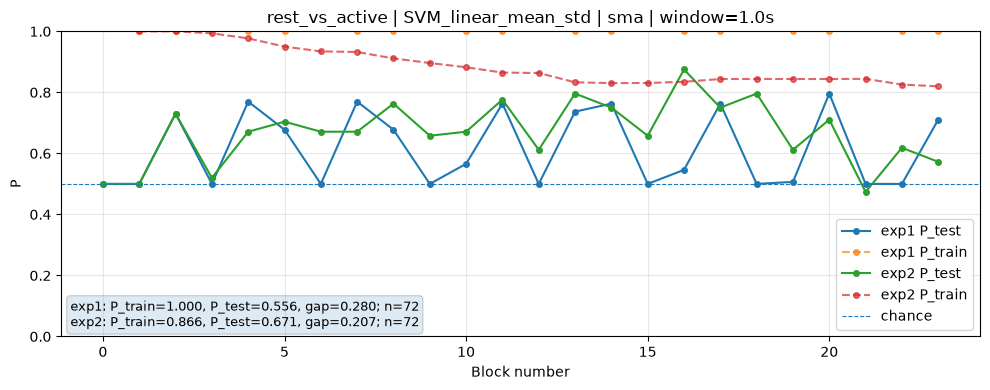

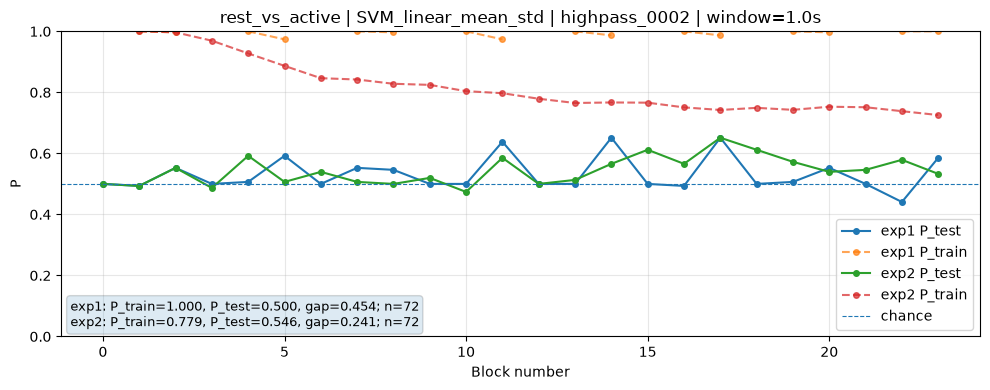

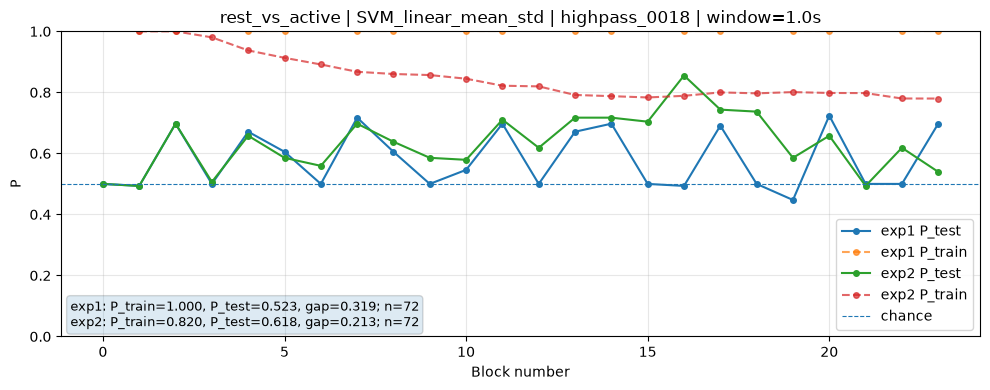

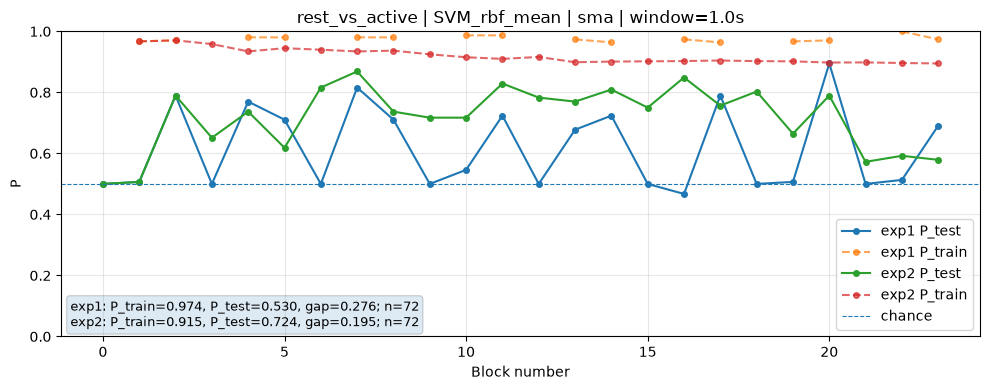

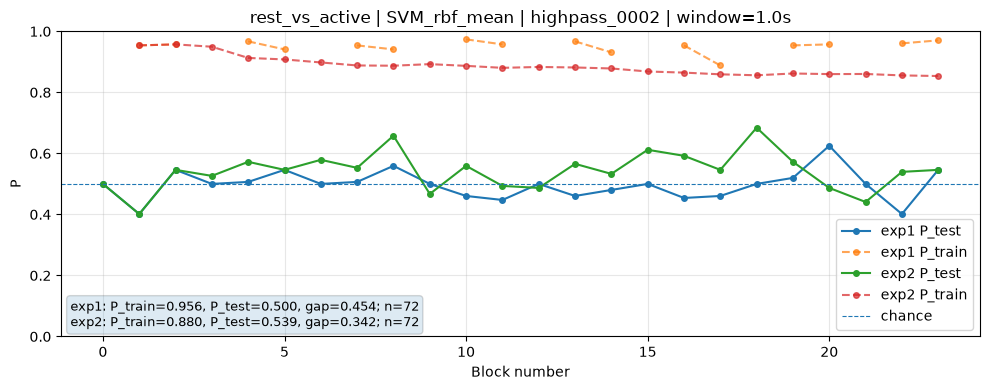

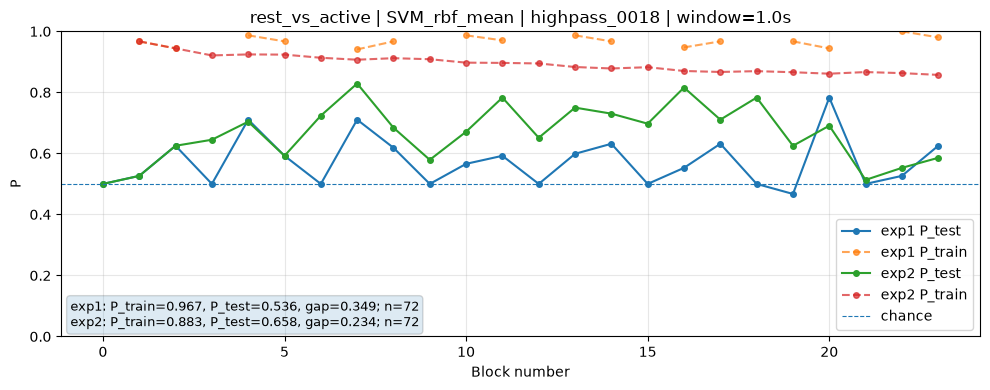

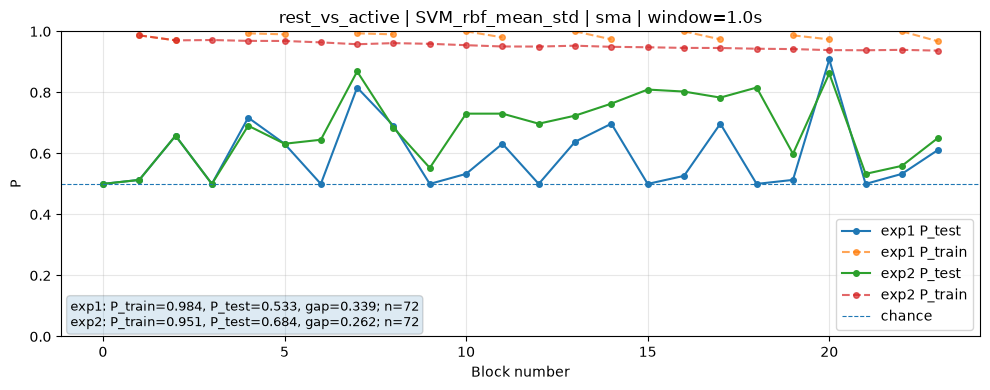

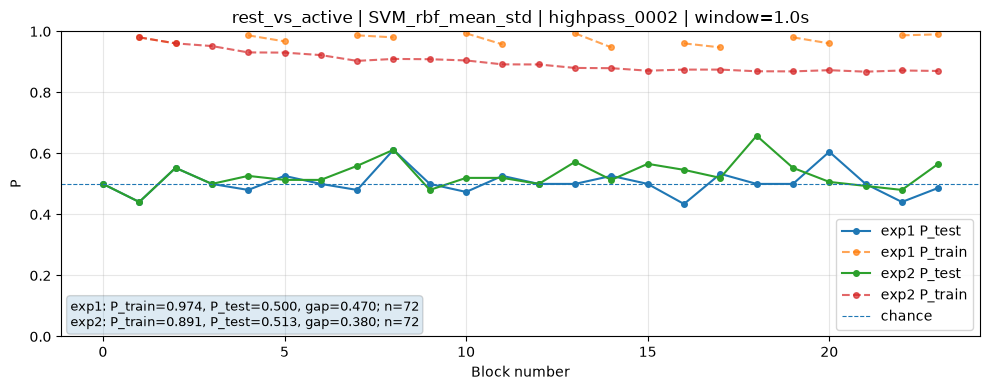

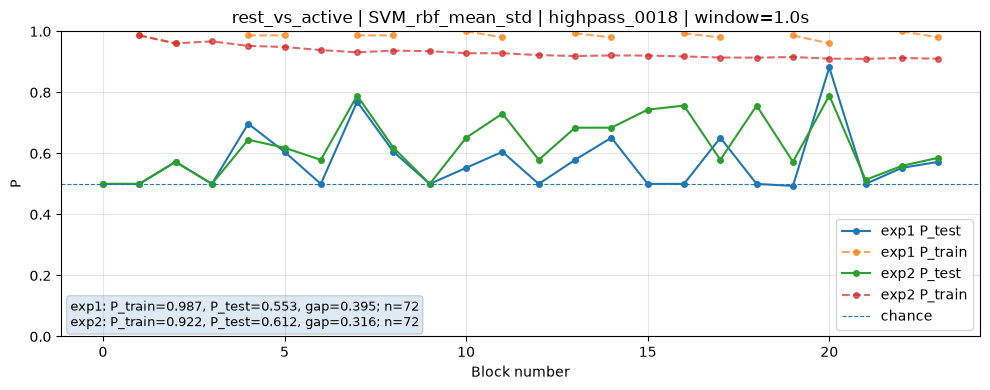

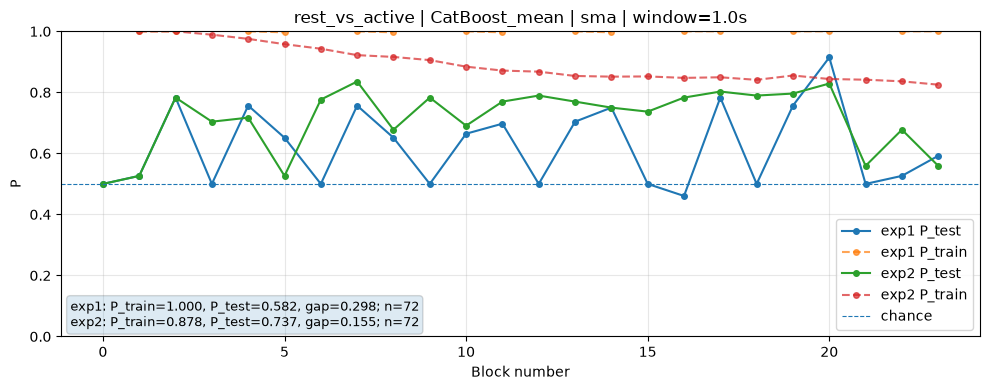

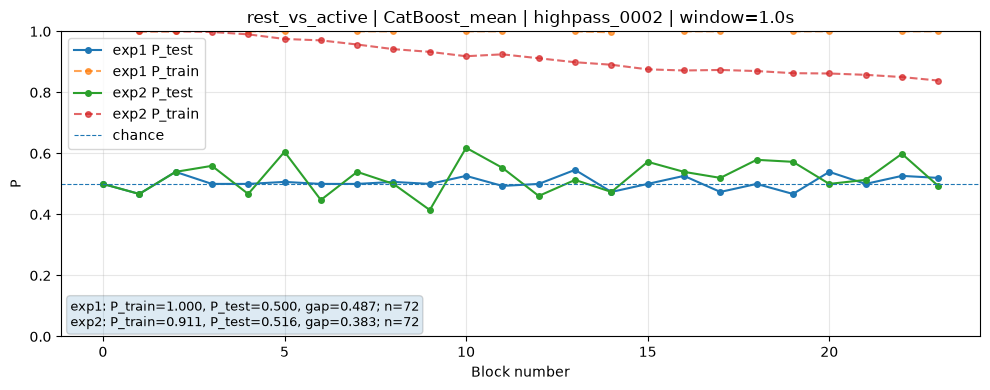

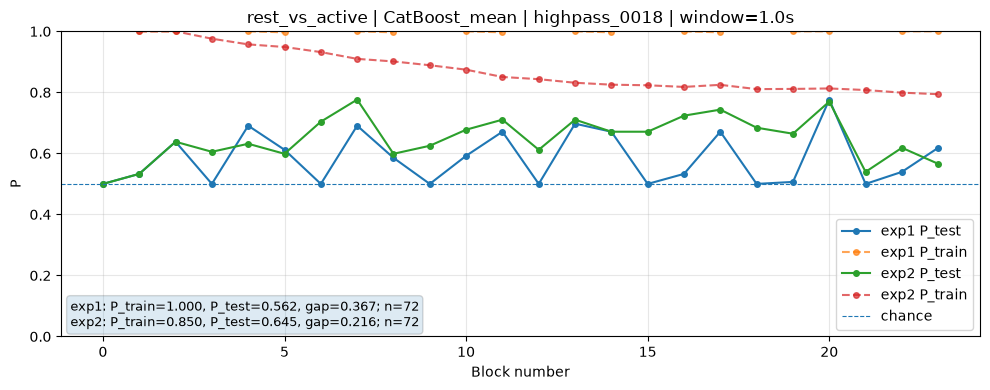

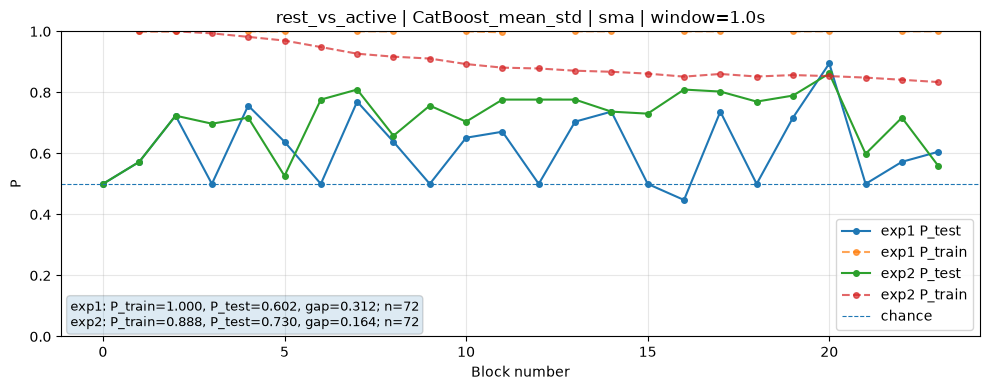

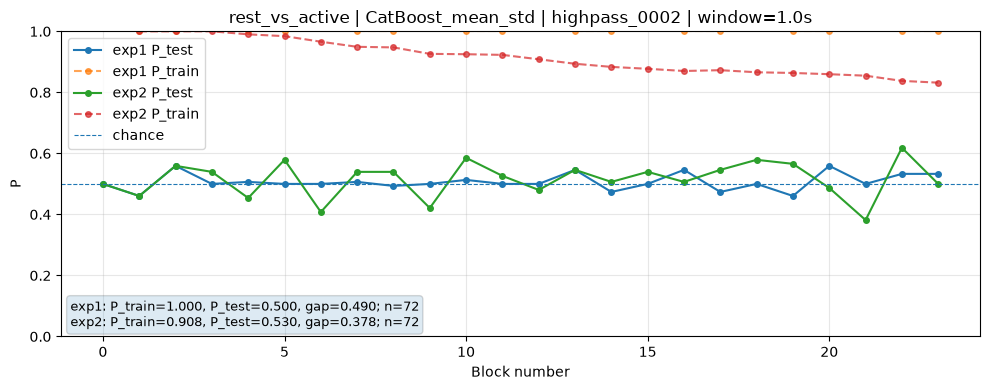

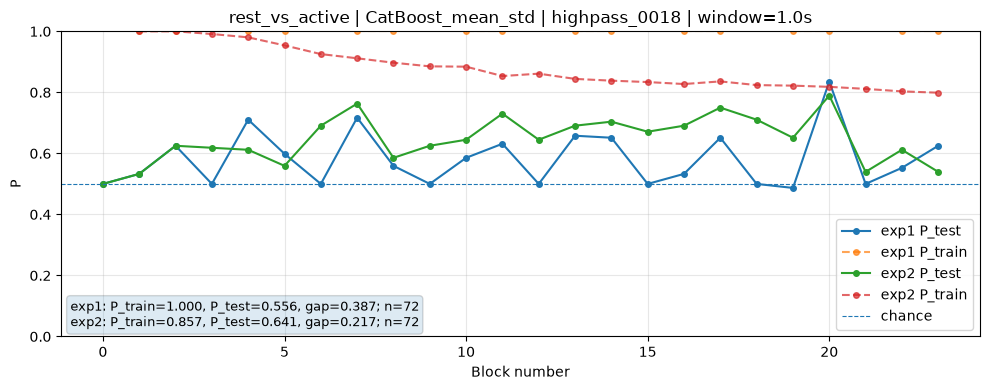

In [10]:
for task in TASKS:
    for clf_name in CLASSIFIERS:
        for filter_mode in TASK_FILTERS[task]:
            fig, ax = plot_dissertation_style_with_summary(
                results_exp1=results_exp1_ml,
                results_exp2=results_exp2_ml,
                task=task,
                clf_name=clf_name,
                filter_mode=filter_mode,
                window_sec=WINDOW_SEC,
                figsize=(10, 4),
            )

            file_name = f"{task}__{clf_name}__{filter_mode}__w{WINDOW_SEC}.png"

            plt.show()

            fig.savefig(prev_dir / file_name, dpi=200, bbox_inches="tight")

            plt.close(fig)


### Вывод по обучению на предыдущих блоках и сессиях

Были проверены две схемы накопления обучающих данных.

- `exp1`: для текущего блока модель обучалась только на предыдущих блоках той же сессии.
- `exp2`: для текущего блока модель обучалась на всех предыдущих блоках, включая предыдущие сессии.

## Вывод по эксперименту с предыдущими блоками и сессиями

В задаче `left_vs_right` все рассмотренные модели — LDA, SVM и CatBoost — показали качество, близкое к случайному уровню. При этом значения `P_train` существенно превышают `P_test`, что указывает на переобучение и слабую переносимость классификационного правила между блоками и сессиями. Возможно, проблема различения левой и правой руки в текущих данных не решается простым переходом к более гибким ML-моделям.

В задаче `rest_vs_active` качество заметно выше случайного уровня. Наиболее устойчивым остаётся LDA: при сопоставимом тестовом качестве он имеет меньший разрыв между `P_train` и `P_test`, чем SVM с RBF-ядром. SVM и CatBoost с текущими параметрами не дают явного устойчивого преимущества над LDA.

Добавление более сложных признаков окна не обязательно улучшает качество. В частности, для SVM добавление `std` к `mean` не даёт прироста и может усиливать переобучение. Поэтому для малых обучающих выборок предпочтительнее использовать более компактные наборы признаков.